# Bounded 2015–2021 Model-Normalized Historical VKT Sensitivity Analysis

**Methodological Gate (`eligibility_status = not_validated_for_ncdb08_rates`):** Transport Canada's Table 10 series (*Commercial Vehicle Safety in Canada: 2012–2021 Annual Report to Parliament*, series `tc_2021_parliament_table10_tractor`) reports econometric/forecast estimates of travel by tractor-trailers with gross vehicle weight $> 15,000\text{ kg}$ for 2015–2021. Because NCDB code `V_TYPE = '08'` covers road tractors with or without semitrailers (including bobtail tractors), lacks a weight threshold, and covers police-reported domestic-road casualty collisions regardless of jurisdiction of registration, Table 10 does not pass the primary-risk denominator gate (`docs/exposure_compatibility_audit.md`).

All ratios in this notebook are **model-normalized historical sensitivities** relative to the Table 10 model trajectory (`events_per_billion_modeled_vkt`, `fatal_events_per_billion_modeled_vkt`, `injury_events_per_billion_modeled_vkt`, and `2015 = 100` index values), **not** unqualified national semi-driving risk rates. Raw event counts and modeled billion VKT are always shown alongside every ratio.

In [1]:
from pathlib import Path
import csv
import json
import math
import duckdb
from IPython.display import Image, Markdown, display

root = Path.cwd()
if not (root / "src").exists():
    root = root.parent

from truck_collisions.analyze_vkt_sensitivity import run_analysis

summary = run_analysis(root)
display(summary)
display(Markdown((root / "docs/model_normalized_vkt_sensitivity.md").read_text(encoding="utf-8")))

{'created_at_utc': '2026-11-08T05:58:49.239041+00:00',
 'analysis': 'bounded_2015_2021_model_normalized_vkt_sensitivity',
 'overlap_years': [2015, 2016, 2017, 2018, 2019, 2020, 2021],
 'decision_gate': 'model_normalized_historical_sensitivity_only_not_approved_as_primary_national_risk_rate',
 'annual_rows': 42,
 'summary_rows': 114,
 'outputs': {'annual_csv': 'reports/tables/vkt_sensitivity_annual.csv',
             'summary_csv': 'reports/tables/vkt_sensitivity_summary.csv',
             'figure_png': 'reports/figures/vkt_model_normalized_sensitivity.png'},
 'inputs_sha256': {'data/derived/ncdb/collisions.parquet': 'a0417eb0cb5f0da6417fce387eba7d0063362f9fd198a55117330ccd09b29688',
                   'data/derived/ncdb/reconciliation.csv': '115d898996e8ea68ca9ffac50c31bbbfd28b45b139efb852de9cb68bf885a687',
                   'data/reference/tractor_exposure_candidates.csv': '3faa5533286a8ac39694d073bc9566ef9d31259daf4fd26235fa44871a78bf99',
                   'data/reference/tractor_e

# Bounded 2015–2021 model-normalized historical VKT sensitivity analysis

Completed 2026-11-08. Companion code: [`src/truck_collisions/analyze_vkt_sensitivity.py`](../src/truck_collisions/analyze_vkt_sensitivity.py). Executed notebook: [`notebooks/08_model_normalized_vkt_sensitivity.ipynb`](../notebooks/08_model_normalized_vkt_sensitivity.ipynb). Output tables: [`reports/tables/vkt_sensitivity_annual.csv`](../reports/tables/vkt_sensitivity_annual.csv) and [`reports/tables/vkt_sensitivity_summary.csv`](../reports/tables/vkt_sensitivity_summary.csv). Figure: [`reports/figures/vkt_model_normalized_sensitivity.png`](../reports/figures/vkt_model_normalized_sensitivity.png).

## Methodological gate and compatibility assumptions

Per the controlling decision in [`docs/exposure_compatibility_audit.md`](exposure_compatibility_audit.md) and [`docs/exposure_methods_review.md`](exposure_methods_review.md), Transport Canada's Table 10 modeled tractor-trailer vehicle-kilometres (`series_id = tc_2021_parliament_table10_tractor`, from *Commercial Vehicle Safety in Canada — 2021 Annual Report to Parliament*, Table 10, p. 45 / PDF p. 57) is **not approved as a primary national road-tractor driving-risk denominator**.

All ratios computed in this phase are explicitly bounded **model-normalized historical sensitivities** for the seven overlapping calendar years **2015–2021**, subject to four explicit compatibility assumptions and boundaries:

1. **Vehicle-class and weight boundary:** NCDB vehicle type `08` ("road tractor with or without semi-trailer") is a physical configuration class with no public gross-vehicle-weight field. Table 10 models "tractor-trailers >15,000 kg". Neither the below-15,000 kg tractor share nor the bobtail (tractor without semitrailer) distance treatment in the econometric model is verifiable from public documentation.
2. **Geographic and fleet-registration boundary:** Public NCDB collision events occur on Canadian public roads regardless of where the involved tractor is registered. The Table 10 econometric model draws on the Canadian Vehicle Survey (CVS) and Canadian Vehicle Use Study (CVUS), which sample Canadian-registered vehicles; adjustments for Canadian-registered travel in the United States, US-registered tractor travel on Canadian roads, and territorial coverage are undocumented in the published report.
3. **Econometric forecast trajectory (including 2020–2021 pandemic years):** Table 10 is an econometric forecast that grows monotonically by ~4.9%–5.0% per year across all seven years (`34,203.5` million km in 2015 to `45,593.8` million km in 2021, or `+33.30%`), including `+4.90%` in 2019–2020 and `+4.90%` in 2020–2021. By contrast, a separate Transport Canada summary for broader commercial vehicles (straight trucks, tractor-trailers, and commercial buses) reported a `-12%` VKT contraction in 2020 followed by a `+16%` rebound in 2021. Consequently, pre-pandemic (`2015–2019`) and pandemic-inclusive (`2015–2021`) windows must be evaluated separately.
4. **Severity scope and counting units:** Public NCDB microdata covers fatal (`C_SEV='1'`) and injury (`C_SEV='2'`) collisions only, excluding property-damage-only (PDO) crashes. Unique tractor-involved collision events ($E_y / \hat{K}_y$, system event incidence per billion modeled VKT) and distinct tractor vehicle involvements ($I_y / \hat{K}_y$, vehicle involvement incidence per billion modeled VKT) are distinct estimands and are reported separately alongside raw event/vehicle counts and modeled billion VKT.

---

## Annual model-normalized sensitivity (2015–2021): primary observed events

The primary numerator counts unique road-tractor casualty collision events (`is_road_tractor = true`, one record per `(source_id, C_YEAR, C_CASE)`). Every ratio is accompanied by its exact raw event count and Table 10 modeled billion VKT:

| Year | Fatal events | Injury events | Total casualty events | Fatal share (%) | Modeled VKT (billion km) | Casualty events / B modeled VKT | Fatal events / B modeled VKT | Injury events / B modeled VKT | Casualty rate index (2015=100) | Fatal rate index (2015=100) |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| 2015 | 194 | 2,881 | 3,075 | 6.31% | 34.2035 | 89.903 | 5.672 | 84.231 | 100.0 | 100.0 |
| 2016 | 193 | 2,817 | 3,010 | 6.41% | 35.8980 | 83.849 | 5.376 | 78.472 | 93.3 | 94.8 |
| 2017 | 216 | 2,962 | 3,178 | 6.80% | 37.6513 | 84.406 | 5.737 | 78.669 | 93.9 | 101.1 |
| 2018 | 190 | 2,800 | 2,990 | 6.35% | 39.4947 | 75.706 | 4.811 | 70.896 | 84.2 | 84.8 |
| 2019 | 196 | 2,579 | 2,775 | 7.06% | 41.4344 | 66.973 | 4.730 | 62.243 | 74.5 | 83.4 |
| 2020 | 158 | 1,964 | 2,122 | 7.45% | 43.4635 | 48.823 | 3.635 | 45.187 | 54.3 | 64.1 |
| 2021 | 169 | 2,107 | 2,276 | 7.43% | 45.5938 | 49.919 | 3.707 | 46.212 | 55.5 | 65.4 |

### Key patterns in the primary series
- **Pre-pandemic trajectory (2015–2019):** Observed casualty events declined `-9.76%` (`3,075 → 2,775`, driven by injury events falling `-10.48%` while fatal events were `+1.03%`, `194 → 196`). Because Table 10 modeled VKT grew `+21.14%` (`34.2035 → 41.4344` billion km), the model-normalized casualty event ratio fell **`-25.50%`** (`89.903 → 66.973` events per billion modeled VKT), and the model-normalized fatal event ratio fell **`-16.60%`** (`5.672 → 4.730` fatal events per billion modeled VKT).
- **Pre-pandemic excluding 2019 (`2015 vs 2018`):** Because 2019 had a former legacy-CSV jurisdiction omission (repaired via the official 2019 XLSX, leaving only a 2-injury-event gap against published Table 1), stopping at 2018 provides a 2019-free pre-pandemic check. From 2015 to 2018, raw casualty events fell `-2.76%` (`3,075 → 2,990`) while modeled VKT rose `+15.47%` (`34.2035 → 39.4947` billion km), yielding a **`-15.79%`** change in casualty events per billion modeled VKT (`89.903 → 75.706`) and **`-15.18%`** in fatal events per billion modeled VKT (`5.672 → 4.811`).
- **Full overlap window (`2015 vs 2021`):** Across the full seven-year overlap, observed casualty events fell `-25.98%` (`3,075 → 2,276`; fatal `-12.89%`, `194 → 169`; injury `-26.87%`, `2,881 → 2,107`) while modeled VKT increased `+33.30%` (`34.2035 → 45.5938` billion km). Relative to Table 10, casualty events per billion modeled VKT declined **`-44.47%`** (`89.903 → 49.919`) and fatal events per billion modeled VKT declined **`-34.65%`** (`5.672 → 3.707`).
- **Table 10 vs. Figure 28 precision check:** Using the 2-decimal-place values from Figure 28 (`34.2035` to `45.59381` billion km) changes annual casualty rates per billion VKT by at most `0.000093` events per billion km (less than `0.00012%`).

---

## Pooled period comparisons (early vs. pre-pandemic vs. full late windows)

Pooling multi-year windows reduces single-year noise. Ratios in pooled windows divide summed events by summed modeled VKT (volume-weighted pooling):

| Comparison / Window | Years | Fatal events | Injury events | Total events | Modeled VKT (B km) | Casualty events / B VKT | Fatal events / B VKT | Injury events / B VKT | Fatal share (%) |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Early window (`2015_2017`) | 2015–2017 | 603 | 8,660 | 9,263 | 107.7528 | 85.965 | 5.596 | 80.369 | 6.51% |
| Pre-pandemic late (`2018_2019_pre_pandemic`) | 2018–2019 | 386 | 5,379 | 5,765 | 80.9291 | 71.235 | 4.770 | 66.466 | 6.70% |
| Pre-pandemic late excl. 2019 (`2018` only) | 2018 | 190 | 2,800 | 2,990 | 39.4947 | 75.706 | 4.811 | 70.896 | 6.35% |
| Full late window (`2018_2021_full_late`) | 2018–2021 | 713 | 9,450 | 10,163 | 169.9864 | 59.787 | 4.194 | 55.593 | 7.02% |
| Full late excl. 2019 (`2018_2021_excl_2019`) | 2018, 2020–2021 | 517 | 6,871 | 7,388 | 128.5520 | 57.471 | 4.022 | 53.449 | 7.00% |
| Pandemic years (`2020_2021_pandemic`) | 2020–2021 | 327 | 4,071 | 4,398 | 89.0573 | 49.384 | 3.672 | 45.712 | 7.44% |
| Full pre-pandemic (`2015_2019_pre_pandemic_all`) | 2015–2019 | 989 | 14,039 | 15,028 | 188.6819 | 79.647 | 5.242 | 74.406 | 6.58% |
| Complete overlap (`2015_2021_all_overlap`) | 2015–2021 | 1,316 | 18,110 | 19,426 | 277.7392 | 69.943 | 4.738 | 65.205 | 6.77% |

### Pooled period percentage changes (Primary observed events)
- **`2015–2017` vs. `2018–2019` (pre-pandemic pooled):** Casualty events per billion modeled VKT changed by **`-17.13%`** (`85.965 → 71.235`, `-14.730` events/B km); fatal events per billion modeled VKT changed by **`-14.77%`** (`5.596 → 4.770`, `-0.827` fatal events/B km); injury events per billion modeled VKT changed by **`-17.30%`** (`80.369 → 66.466`).
- **`2015–2017` vs. `2018` (pre-pandemic pooled, excluding 2019):** Casualty events per billion modeled VKT changed by **`-11.93%`** (`85.965 → 75.706`); fatal events per billion modeled VKT changed by **`-14.03%`** (`5.596 → 4.811`).
- **`2015–2017` vs. `2018–2021` (full window pooled):** Casualty events per billion modeled VKT changed by **`-30.45%`** (`85.965 → 59.787`); fatal events per billion modeled VKT changed by **`-25.05%`** (`5.596 → 4.194`).
- **`2015–2017` vs. `2018, 2020–2021` (full window pooled, excluding 2019):** Casualty events per billion modeled VKT changed by **`-33.15%`** (`85.965 → 57.471`); fatal events per billion modeled VKT changed by **`-28.13%`** (`5.596 → 4.022`).

---

## Numerator and estimand sensitivities

To verify that findings do not depend on record-quality exclusions, the 2019 publication benchmark difference, or the choice between collision events ($E_y$) and vehicle involvements ($I_y$), [`reports/tables/vkt_sensitivity_annual.csv`](../reports/tables/vkt_sensitivity_annual.csv) and [`reports/tables/vkt_sensitivity_summary.csv`](../reports/tables/vkt_sensitivity_summary.csv) evaluate six distinct numerator specifications:

| Numerator specification | Counting unit | 2015 count | 2019 count | 2021 count | 2015 rate / B VKT | 2019 rate / B VKT | 2021 rate / B VKT | 2015→2019 rate change | 2015→2021 rate change | 2015–17 vs 2018–19 pooled change | 2015–17 vs 2018–21 pooled change |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| `primary_observed_events` | Unique collision event | 3,075 | 2,775 | 2,276 | 89.903 | 66.973 | 49.919 | -25.50% | -44.47% | -17.13% | -30.45% |
| `strict_candidate_events` | Unique collision event (`is_analysis_candidate`) | 3,075 | 2,775 | 2,275 | 89.903 | 66.973 | 49.897 | -25.50% | -44.50% | -17.12% | -30.48% |
| `strict_zero_unknown_vtype_events` | Unique event (zero unknown/other `V_TYPE`) | 3,031 | 2,732 | 2,240 | 88.617 | 65.936 | 49.129 | -25.59% | -44.56% | -17.15% | -30.57% |
| `published_tc_benchmark_events` | Published TC Table 1 collision events | 3,075 | 2,777 | 2,276 | 89.903 | 67.022 | 49.919 | -25.45% | -44.47% | -17.11% | -30.44% |
| `observed_tractor_vehicle_involvements` | Distinct tractor vehicle (`V_TYPE='08'`) | 3,282 | 3,040 | 2,459 | 95.955 | 73.369 | 53.933 | -23.54% | -43.79% | -15.32% | -28.88% |
| `strict_tractor_vehicle_involvements` | Distinct tractor vehicle in strict events | 3,282 | 3,040 | 2,458 | 95.955 | 73.369 | 53.911 | -23.54% | -43.82% | -15.29% | -29.02% |

### Sensitivity takeaways
1. **Strict structural filtering (`strict_candidate_events`) and strict zero-unknown-vehicle-type filtering (`strict_zero_unknown_vtype_events`):** Removing the 9 strict-excluded collisions in 2015–2021 (2 in 2017, 6 in 2020, 1 in 2021) or additionally excluding the ~1.4% of tractor collisions that also involve an unknown/other vehicle type (`has_unknown_vehicle_type`) shifts the 2015–2019 and 2015–2021 percentage changes by less than `0.10` percentage points.
2. **2019 published benchmark alternative (`published_tc_benchmark_events`):** Substituting Transport Canada's published 2019 injury count (`2,581` vs. `2,579` in the official 2019 XLSX microdata) changes the 2019 casualty rate from `66.973` to `67.022` per billion modeled VKT (`+0.048` events/B km) and alters the 2015–2017 vs. 2018–2019 pooled change from `-17.13%` to `-17.11%`.
3. **Vehicle-involvement estimand (`observed_tractor_vehicle_involvements`):** Because `5.9%–6.9%` of tractor collisions in 2015–2021 involve two or more road tractors (`1,241` multi-tractor collisions across the 7 years), distinct tractor involvements ($I_y$) exceed unique events ($E_y$) by `6.6%–8.6%` (`20,997` tractor involvements vs. `19,426` unique collisions in 2015–2021). Involvement rates per billion modeled VKT decline by **`-23.54%`** over 2015–2019 (`95.955 → 73.369`) and **`-43.79%`** over 2015–2021 (`95.955 → 53.933`). Notably, fatal tractor vehicle involvements per billion modeled VKT rose to a peak in 2017 (`7.012` fatal tractor involvements/B km, `264` involvements in `216` fatal crashes) before declining to `5.768` in 2019 and `4.540` in 2021 (`-24.62%` over 2015–2021).

---

## Summary of allowed and disallowed conclusions

- **Allowed conclusion:** Relative to Transport Canada's Table 10 econometric VKT series (`34.20` to `45.59` billion km), observed NCDB road-tractor casualty events per billion modeled kilometres declined by `17.13%` between pooled `2015–2017` and pre-pandemic `2018–2019` (`11.93%` when excluding 2019), and by `30.45%` between `2015–2017` and `2018–2021` (`44.47%` endpoint decline from 2015 to 2021). Fatal events per billion modeled kilometres declined by `14.77%` in the pre-pandemic pooled comparison (`14.03%` excluding 2019) and `25.05%` across the full pooled comparison (`34.65%` from 2015 to 2021).
- **Disallowed conclusion:** Because Table 10 is an unverified econometric forecast with unresolved class (`>15,000 kg` vs. all `V_TYPE='08'`), attachment, and domestic/cross-border geography boundaries—and because its uninterrupted 2020–2021 growth (`+4.9%/yr`) contrasts with other Transport Canada commercial traffic indicators—these model-normalized ratios **must not** be cited as validated national semi-driving risk rates or used to attribute causal safety effects to regulations or pandemic traffic changes.


In [2]:
# Independent DuckDB verification of annual and period-pooled model-normalized VKT sensitivity tables.
con = duckdb.connect()

vkt_rows = list(csv.DictReader((root / "data/reference/tractor_exposure_candidates.csv").open(encoding="utf-8")))
vkt_by_year = {int(r["year"]): float(r["vkt_million_km"]) / 1000.0 for r in vkt_rows}
assert set(vkt_by_year.keys()) == set(range(2015, 2022))
assert all(r["eligibility_status"] == "not_validated_for_ncdb08_rates" for r in vkt_rows)

collision_counts = {
    int(y): {
        "primary_observed_events": (int(f_obs), int(i_obs), int(t_obs)),
        "strict_candidate_events": (int(f_str), int(i_str), int(t_str)),
        "strict_zero_unknown_vtype_events": (int(f_zero), int(i_zero), int(t_zero)),
        "observed_tractor_vehicle_involvements": (int(vf_obs), int(vi_obs), int(vt_obs)),
        "strict_tractor_vehicle_involvements": (int(vf_str), int(vi_str), int(vt_str)),
    }
    for y, f_obs, i_obs, t_obs, f_str, i_str, t_str, f_zero, i_zero, t_zero, vf_obs, vi_obs, vt_obs, vf_str, vi_str, vt_str in con.execute(
        """
        SELECT
            C_YEAR,
            count(*) FILTER (WHERE C_SEV = '1'),
            count(*) FILTER (WHERE C_SEV = '2'),
            count(*),
            count(*) FILTER (WHERE is_analysis_candidate AND C_SEV = '1'),
            count(*) FILTER (WHERE is_analysis_candidate AND C_SEV = '2'),
            count(*) FILTER (WHERE is_analysis_candidate),
            count(*) FILTER (WHERE is_analysis_candidate AND NOT has_unknown_vehicle_type AND C_SEV = '1'),
            count(*) FILTER (WHERE is_analysis_candidate AND NOT has_unknown_vehicle_type AND C_SEV = '2'),
            count(*) FILTER (WHERE is_analysis_candidate AND NOT has_unknown_vehicle_type),
            sum(road_tractor_vehicle_count) FILTER (WHERE C_SEV = '1'),
            sum(road_tractor_vehicle_count) FILTER (WHERE C_SEV = '2'),
            sum(road_tractor_vehicle_count),
            sum(road_tractor_vehicle_count) FILTER (WHERE is_analysis_candidate AND C_SEV = '1'),
            sum(road_tractor_vehicle_count) FILTER (WHERE is_analysis_candidate AND C_SEV = '2'),
            sum(road_tractor_vehicle_count) FILTER (WHERE is_analysis_candidate)
        FROM read_parquet(?)
        WHERE is_road_tractor AND C_YEAR BETWEEN 2015 AND 2021
        GROUP BY C_YEAR
        ORDER BY C_YEAR
        """,
        [str(root / "data/derived/ncdb/collisions.parquet")],
    ).fetchall()
}
con.close()

reconciliation_rows = {
    int(r["year"]): (
        int(r["published_fatal"]),
        int(r["published_injury"]),
        int(r["published_fatal"]) + int(r["published_injury"]),
    )
    for r in csv.DictReader((root / "data/derived/ncdb/reconciliation.csv").open(encoding="utf-8"))
    if 2015 <= int(r["year"]) <= 2021
}
for y, pub_tuple in reconciliation_rows.items():
    collision_counts[y]["published_tc_benchmark_events"] = pub_tuple

annual_csv = list(csv.DictReader((root / "reports/tables/vkt_sensitivity_annual.csv").open(encoding="utf-8")))
assert len(annual_csv) == 42

base_rates = {}
for r in annual_csv:
    if int(r["year"]) == 2015:
        base_rates[r["numerator_id"]] = (
            float(r["events_per_billion_modeled_vkt"]),
            float(r["fatal_events_per_billion_modeled_vkt"]),
            float(r["injury_events_per_billion_modeled_vkt"]),
        )

for r in annual_csv:
    y = int(r["year"])
    spec = r["numerator_id"]
    f_exp, i_exp, t_exp = collision_counts[y][spec]
    vkt_b = vkt_by_year[y]
    assert (int(r["fatal_events"]), int(r["injury_events"]), int(r["total_casualty_events"])) == (f_exp, i_exp, t_exp)
    assert f_exp + i_exp == t_exp
    assert math.isclose(float(r["modeled_vkt_billion_km"]), vkt_b, abs_tol=1e-9)
    assert math.isclose(float(r["events_per_billion_modeled_vkt"]), t_exp / vkt_b, abs_tol=1e-6)
    assert math.isclose(float(r["fatal_events_per_billion_modeled_vkt"]), f_exp / vkt_b, abs_tol=1e-6)
    assert math.isclose(float(r["injury_events_per_billion_modeled_vkt"]), i_exp / vkt_b, abs_tol=1e-6)
    b_tot, b_fat, b_inj = base_rates[spec]
    assert math.isclose(float(r["events_per_billion_vkt_index_2015_100"]), 100.0 * (t_exp / vkt_b) / b_tot, abs_tol=1e-4)
    assert math.isclose(float(r["fatal_per_billion_vkt_index_2015_100"]), 100.0 * (f_exp / vkt_b) / b_fat, abs_tol=1e-4)
    assert math.isclose(float(r["injury_per_billion_vkt_index_2015_100"]), 100.0 * (i_exp / vkt_b) / b_inj, abs_tol=1e-4)

summary_csv = list(csv.DictReader((root / "reports/tables/vkt_sensitivity_summary.csv").open(encoding="utf-8")))
assert len(summary_csv) == 114
print(f"Verified {len(annual_csv)} annual rows and {len(summary_csv)} summary rows against independent DuckDB queries.")

Verified 42 annual rows and 114 summary rows against independent DuckDB queries.


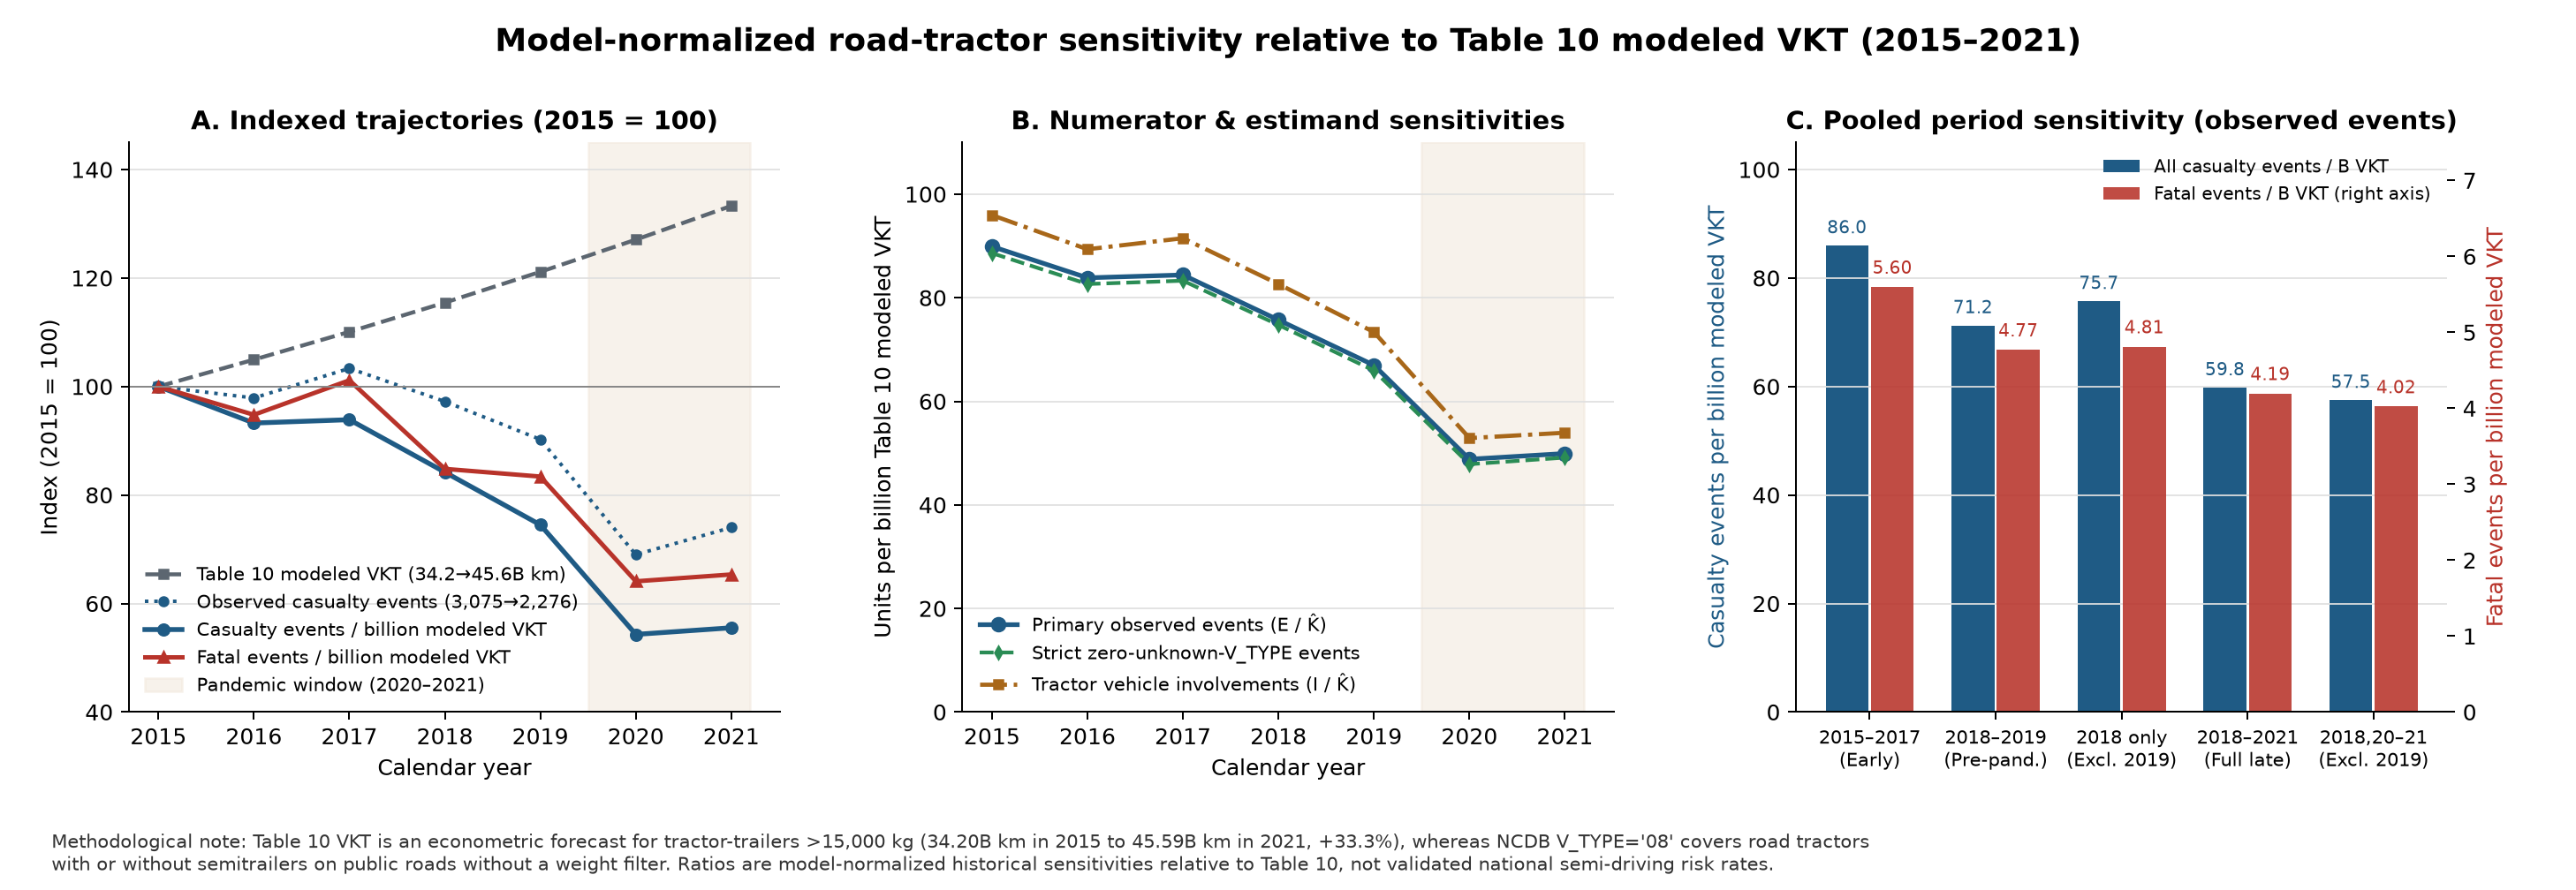

In [3]:
display(Image(filename=str(root / "reports/figures/vkt_model_normalized_sensitivity.png")))